# Q3 — Profils de ponctualité des liaisons TGV (clustering)

**Question** : peut-on regrouper les liaisons par « profil de ponctualité »
(bonne régularité, retards chroniques mineurs, retards rares mais sévères…)
à l'aide d'un clustering ?

**Type de question** : exploratoire — on cherche une structure naturelle dans les données.
Ce qu'on a le droit de conclure : « les liaisons se répartissent en *k* groupes
au comportement distinct, voici leurs caractéristiques ».
Ce qu'on n'a **pas** le droit de dire : pourquoi une liaison est dans tel groupe
(causalité), ni qu'un groupe « existe vraiment » sans validation de robustesse.

---

## Plan
1. Imports & constantes
2. Chargement et aperçu
3. Hypothèses a priori *(à remplir avant d'exécuter la suite)*
4. Mois exceptionnels (COVID, grandes grèves)
5. Construction des indicateurs par liaison
6. Seuil d'éligibilité (petites liaisons)
7. Distributions et redondance
8. Mise à l'échelle
9. Choix du nombre de profils (coude + silhouette)
10. K-Means — ajustement et description
11. Nommage des profils
12. Visualisations finales
13. Robustesse : la structure est-elle stable ?
14. Sauvegarde pour l'app
15. Conclusions

## 0. Hypothèses a priori

> **À remplir AVANT d'exécuter la suite** — exercice pédagogique de l'EDA :
> noter ses attentes évite de sur-interpréter les résultats.

- **H1** : il devrait exister un groupe de liaisons très fiables (grandes lignes structurantes)
- **H2** : certaines liaisons affichent des retards fréquents mais courts (flux pendulaire à fort volume)
- **H3** : quelques liaisons ont des retards rares mais sévères (liaisons longues / à risque)
- **H4** : un groupe « mauvais élèves » cumulant annulations et retards importants

*Comparer aux profils réels en section 11.*

In [1]:
# ── 1. Imports & constantes ──────────────────────────────────────────────────
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", "{:.4f}".format)
SEED = 42  # reproductibilité obligatoire (cours Charlotte, session 1)

RAW_PATH = Path("../data/raw/regularite-mensuelle-tgv-aqst.csv")
PROCESSED_DIR = Path("../data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
print("Tout importé.")

Matplotlib is building the font cache; this may take a moment.


Tout importé.


## 2. Chargement et aperçu

In [2]:
raw = pd.read_csv(RAW_PATH, sep=";", encoding="utf-8-sig")
print(f"Shape : {raw.shape}")
raw.head(3)

Shape : (12907, 26)


,Date,Service,Gare de départ,Gare d'arrivée,Durée moyenne du trajet,Nombre de circulations prévues,Nombre de trains annulés,Commentaire annulations,Nombre de trains en retard au départ,Retard moyen des trains en retard au départ,...,Nombre trains en retard > 15min,Retard moyen trains en retard > 15 (si liaison concurrencée par vol),Nombre trains en retard > 30min,Nombre trains en retard > 60min,Prct retard pour causes externes,Prct retard pour cause infrastructure,Prct retard pour cause gestion trafic,Prct retard pour cause matériel roulant,Prct retard pour cause gestion en gare et réutilisation de matériel,"Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)"
0,2018-01,National,BORDEAUX ST JEAN,PARIS MONTPARNASSE,141,870,5,NaN,289,11.2478,...,110,6.5111,44,8,36.1345,31.0924,10.9244,15.9664,5.0420,0.8403
1,2018-01,National,LE MANS,PARIS MONTPARNASSE,56,406,1,NaN,213,8.4800,...,32,5.3635,9,4,20.0000,35.0000,16.6667,16.6667,8.3333,3.3333
2,2018-01,National,PARIS MONTPARNASSE,LA ROCHELLE VILLE,166,226,0,NaN,21,6.2397,...,11,2.9381,6,1,22.2222,27.7778,16.6667,16.6667,5.5556,11.1111


In [3]:
# Renommage en snake_case pour travailler confortablement
COL_MAP = {
    "Date": "date",
    "Service": "service",
    "Gare de départ": "departure",
    "Gare d'arrivée": "arrival",
    "Durée moyenne du trajet": "trip_duration_min",
    "Nombre de circulations prévues": "trains_planned",
    "Nombre de trains annulés": "trains_cancelled",
    "Nombre de trains en retard au départ": "late_departure",
    "Retard moyen des trains en retard au départ": "mean_delay_late_dep",
    "Retard moyen de tous les trains au départ": "mean_delay_all_dep",
    "Nombre de trains en retard à l'arrivée": "late_arrival",
    "Retard moyen des trains en retard à l'arrivée": "mean_delay_late_arr",
    "Retard moyen de tous les trains à l'arrivée": "mean_delay_all_arr",
    "Nombre trains en retard > 15min": "late_15min",
    "Nombre trains en retard > 30min": "late_30min",
    "Nombre trains en retard > 60min": "late_60min",
    "Prct retard pour causes externes": "pct_cause_external",
    "Prct retard pour cause infrastructure": "pct_cause_infra",
    "Prct retard pour cause gestion trafic": "pct_cause_traffic",
    "Prct retard pour cause matériel roulant": "pct_cause_rolling_stock",
    "Prct retard pour cause gestion en gare et réutilisation de matériel": "pct_cause_station_mgmt",
    "Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)": "pct_cause_passengers",
}
df = raw.rename(columns=COL_MAP).copy()

# Colonne liaison unique
df["route"] = df["departure"] + " → " + df["arrival"]

# Trains effectivement circulés (planifié − annulé, au moins 0)
df["trains_run"] = (df["trains_planned"] - df["trains_cancelled"]).clip(lower=0)

print(f"Nombre de liaisons uniques : {df['route'].nunique()}")
print(f"Nombre de mois uniques    : {df['date'].nunique()}")
print(f"Période                   : {df['date'].min()} → {df['date'].max()}")

Nombre de liaisons uniques : 130
Nombre de mois uniques    : 105
Période                   : 2018-01 → 2026-09


In [5]:
# Vérifications de cohérence rapides
print(
    "trains_run négatifs (avant clip) :",
    (df["trains_planned"] - df["trains_cancelled"] < 0).sum(),
)
print("late_arrival > trains_run :", (df["late_arrival"] > df["trains_run"]).sum())
print(
    "Valeurs manquantes par colonne :\n",
    df[
        [
            "trains_planned",
            "trains_cancelled",
            "late_arrival",
            "mean_delay_late_arr",
            "late_30min",
            "late_60min",
        ]
    ]
    .isnull()
    .sum(),
)
print(df.isnull().sum())

trains_run négatifs (avant clip) : 63
late_arrival > trains_run : 0
Valeurs manquantes par colonne :
 trains_planned         0
trains_cancelled       0
late_arrival           0
mean_delay_late_arr    0
late_30min             0
late_60min             0
dtype: int64
date                                                                        0
service                                                                     0
departure                                                                   0
arrival                                                                     0
trip_duration_min                                                           0
trains_planned                                                              0
trains_cancelled                                                            0
Commentaire annulations                                                 12907
late_departure                                                              0
mean_delay_late_dep              

## 4. Mois exceptionnels

Trois événements perturbent structurellement les données :

| Période | Événement | Impact |
|---|---|---|
| 2019-12 → 2020-02 | Grande grève SNCF | Très forte baisse des circulations |
| 2020-03 → 2020-06 | Confinements COVID-19 | Quasi-arrêt du réseau |
| 2022-12 (ponctuel) | Grève de Noël | Impact modéré |

**Choix** : on les exclut du calcul des indicateurs moyens (on ne veut pas qu'un
profil « grève » biaise les clusters), mais on les affiche en contexte.
Cette décision est documentée dans la datasheet (section 4).

Lignes exceptionnelles : 861 (6.7% du total)


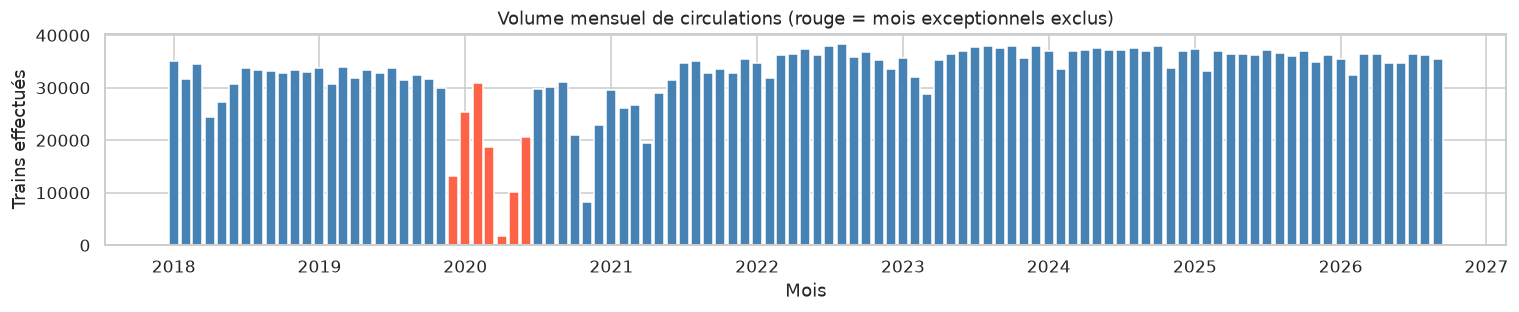

In [11]:
EXCEPTIONAL_MONTHS = [
    "2019-12",
    "2020-01",
    "2020-02",  # grande grève
    "2020-03",
    "2020-04",
    "2020-05",
    "2020-06",  # COVID
]

df["is_exceptional"] = df["date"].isin(EXCEPTIONAL_MONTHS)
print(
    f"Lignes exceptionnelles : {df['is_exceptional'].sum()} "
    f"({df['is_exceptional'].mean():.1%} du total)"
)

# Visualiser le volume mensuel pour confirmer
monthly_vol = df.groupby("date")["trains_run"].sum().reset_index()
monthly_vol["date_dt"] = pd.to_datetime(monthly_vol["date"])

fig, ax = plt.subplots(figsize=(14, 3))
colors = [
    "tomato" if d in EXCEPTIONAL_MONTHS else "steelblue" for d in monthly_vol["date"]
]
ax.bar(monthly_vol["date_dt"], monthly_vol["trains_run"], color=colors, width=25)
ax.set_title("Volume mensuel de circulations (rouge = mois exceptionnels exclus)")
ax.set_xlabel("Mois")
ax.set_ylabel("Trains effectués")
plt.tight_layout()
plt.show()

## 5. Construction des indicateurs par liaison

L'unité d'analyse pour le clustering est **la liaison** (A → B), pas le mois.
On agrège tous les mois *non exceptionnels* en sommer les volumes puis en
calculant des taux — ce qui revient à une moyenne pondérée par le trafic.

**5 indicateurs** couvrant les dimensions indépendantes :

| Indicateur | Dimension |
|---|---|
| `cancellation_rate` | Fiabilité brute |
| `late_arrival_rate` | Ponctualité |
| `mean_delay_when_late` | Sévérité des retards |
| `severe_ratio` | Proportion de gros retards (>30 min) parmi retards |
| `irregularity` | Variabilité mois-à-mois (instabilité) |

$$\text{mean\_delay\_when\_late} = \frac{\sum_{\text{mois}} \left( \overline{d}_{\text{mois}} \times n^{\text{late}}_{\text{mois}} \right)}{\sum_{\text{mois}} n^{\text{late}}_{\text{mois}}}$$

In [12]:
df_normal = df[~df["is_exceptional"]].copy()

# Agrégation des volumes par liaison
agg = (
    df_normal.groupby("route")
    .agg(
        n_months=("date", "nunique"),
        total_planned=("trains_planned", "sum"),
        total_cancelled=("trains_cancelled", "sum"),
        total_run=("trains_run", "sum"),
        total_late_arr=("late_arrival", "sum"),
        total_late_30=("late_30min", "sum"),
        total_late_60=("late_60min", "sum"),
        # Pour le retard moyen conditionnel : somme pondérée
        sum_delay_x_late=(
            "mean_delay_late_arr",
            lambda x: (x * df_normal.loc[x.index, "late_arrival"]).sum(),
        ),
    )
    .reset_index()
)

# Taux globaux
agg["cancellation_rate"] = agg["total_cancelled"] / agg["total_planned"]
agg["late_arrival_rate"] = agg["total_late_arr"] / agg["total_run"].clip(lower=1)
agg["mean_delay_when_late"] = agg["sum_delay_x_late"] / agg["total_late_arr"].clip(
    lower=1
)
agg["severe_ratio"] = agg["total_late_30"] / agg["total_late_arr"].clip(lower=1)

# Variabilité mois-à-mois du taux de retard (std des taux mensuels)
monthly_rates = (
    df_normal.assign(
        monthly_late_rate=lambda d: d["late_arrival"] / d["trains_run"].clip(lower=1)
    )
    .groupby("route")["monthly_late_rate"]
    .std()
    .rename("irregularity")
)
agg = agg.merge(monthly_rates, on="route", how="left")
agg["irregularity"] = agg["irregularity"].fillna(0)

print(f"Liaisons avec indicateurs : {len(agg)}")
agg[
    [
        "route",
        "n_months",
        "cancellation_rate",
        "late_arrival_rate",
        "mean_delay_when_late",
        "severe_ratio",
        "irregularity",
    ]
].head(8)

Liaisons avec indicateurs : 130


,route,n_months,cancellation_rate,late_arrival_rate,mean_delay_when_late,severe_ratio,irregularity
0,AIX EN PROVENCE TGV → PARIS LYON,98,0.0200,0.1233,47.4306,0.4964,0.0472
1,ANGERS SAINT LAUD → PARIS MONTPARNASSE,98,0.0249,0.1523,32.4664,0.3021,0.0554
2,ANGOULEME → PARIS MONTPARNASSE,98,0.0321,0.1653,32.7751,0.2848,0.0602
3,ANNECY → PARIS LYON,98,0.0309,0.2010,35.5802,0.3603,0.0859
4,ARRAS → PARIS NORD,98,0.0382,0.2175,19.8429,0.1474,0.0609
5,AVIGNON TGV → PARIS LYON,98,0.0220,0.1647,38.2492,0.3720,0.0584
6,BARCELONA → PARIS LYON,98,0.0184,0.2081,46.2833,0.5498,0.1000
7,BELLEGARDE (AIN) → PARIS LYON,98,0.0232,0.1400,36.9943,0.3477,0.0842


## Seuil d'éligibilité

Les liaisons ayant peu de mois d'observation donnent des taux très instables
(un seul mois de grève ou de travaux fausse tout). On garde les liaisons
présentes sur **au moins 24 mois** (≈ 2 ans de données normales).

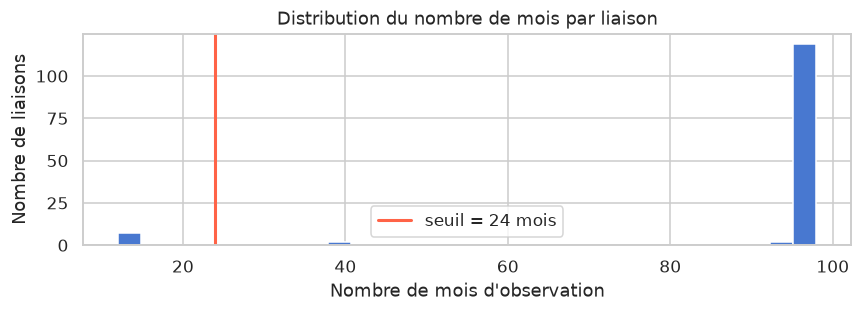

Liaisons éligibles : 123 / 130 (exclus : 7)
Voici les liens exclus: 
                                  route  n_months  total_planned  \
10   BORDEAUX ST JEAN → PARIS VAUGIRARD        12            640   
51             NANTES → PARIS VAUGIRARD        12            607   
106  PARIS VAUGIRARD → BORDEAUX ST JEAN        12            622   
107            PARIS VAUGIRARD → NANTES        12            594   
108            PARIS VAUGIRARD → RENNES        12            314   
115            RENNES → PARIS VAUGIRARD        12            315   
125    TOURCOING → MARSEILLE ST CHARLES        13            306   

     total_cancelled  total_run  total_late_arr  total_late_30  total_late_60  \
10                14        626              93             42             21   
51                 0        607              90             36             21   
106               20        602              65             30             11   
107                0        594              88             42

In [ ]:
MIN_MONTHS = 24

# Distribution du nombre de mois par liaison
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(agg["n_months"], bins=30, edgecolor="white")
ax.axvline(MIN_MONTHS, color="tomato", linewidth=2, label=f"seuil = {MIN_MONTHS} mois")
ax.set_xlabel("Nombre de mois d'observation")
ax.set_ylabel("Nombre de liaisons")
ax.set_title("Distribution du nombre de mois par liaison")
ax.legend()
plt.tight_layout()
plt.show()

agg_eligible = agg[agg["n_months"] >= MIN_MONTHS].copy()
print(
    f"Liaisons éligibles : {len(agg_eligible)} / {len(agg)} "
    f"(exclus : {len(agg) - len(agg_eligible)})"
)

print("Voici les liens exclus: ")
print(agg[agg["n_months"] < MIN_MONTHS])  # on a que 12/105 environ pour ceux ci

## Distributions et redondance des indicateurs

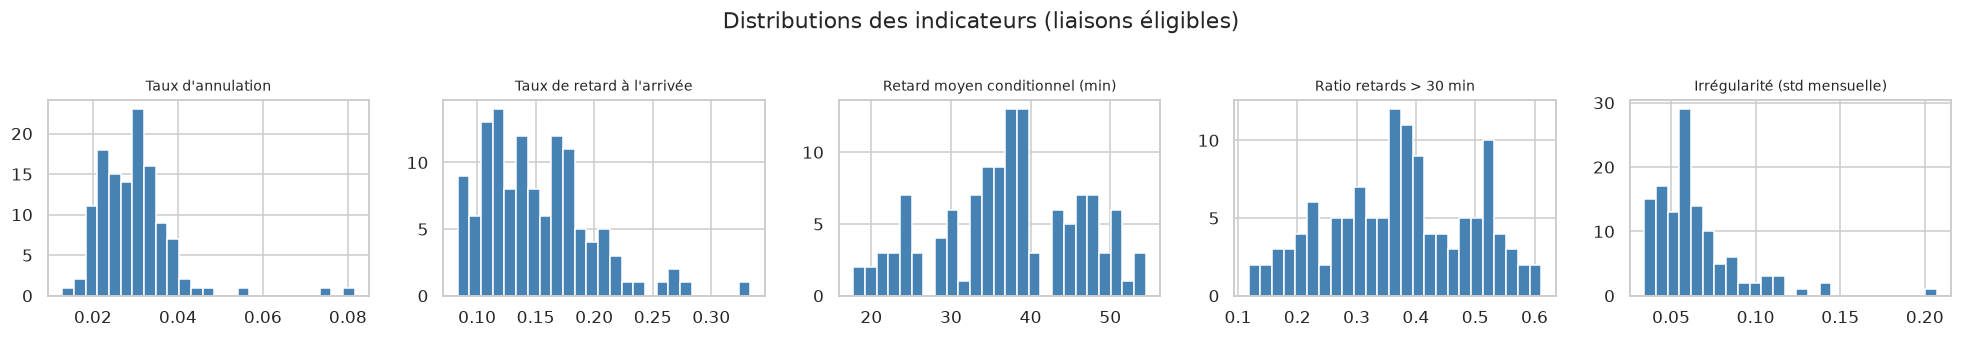

In [ ]:
FEATURES = [
    "cancellation_rate",
    "late_arrival_rate",
    "mean_delay_when_late",
    "severe_ratio",
    "irregularity",
]
FEATURE_LABELS = {
    "cancellation_rate": "Taux d'annulation",
    "late_arrival_rate": "Taux de retard à l'arrivée",
    "mean_delay_when_late": "Retard moyen conditionnel (min)",
    "severe_ratio": "Ratio retards > 30 min",
    "irregularity": "Irrégularité (std mensuelle)",
}

fig, axes = plt.subplots(1, 5, figsize=(18, 3))
for ax, feat in zip(axes, FEATURES):
    ax.hist(agg_eligible[feat].dropna(), bins=25, edgecolor="white", color="steelblue")
    ax.set_title(FEATURE_LABELS[feat], fontsize=9)
    ax.set_xlabel("")
plt.suptitle("Distributions des indicateurs (liaisons éligibles)", y=1.02)
plt.tight_layout()
plt.show()

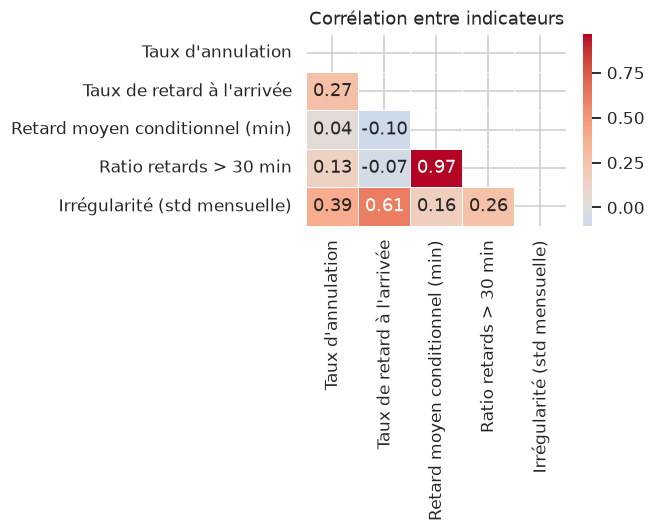

In [16]:
# Matrice de corrélation — détecter les redondances
corr = agg_eligible[FEATURES].corr()

fig, ax = plt.subplots(figsize=(6, 5))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    ax=ax,
    linewidths=0.5,
    xticklabels=[FEATURE_LABELS[f] for f in FEATURES],
    yticklabels=[FEATURE_LABELS[f] for f in FEATURES],
)
ax.set_title("Corrélation entre indicateurs")
plt.tight_layout()
plt.show()

# Commentaire : late_arrival_rate et severe_ratio sont souvent corrélés.
# On garde les deux car severe_ratio capture le "type" de retard,
# pas seulement la fréquence.

## Mise à l'échelle

K-Means est sensible à l'échelle des variables (distance euclidienne).
On applique un `StandardScaler` (moyenne 0, écart-type 1) sur les 5 indicateurs.

In [17]:
X_raw = agg_eligible[FEATURES].fillna(0).values
scaler = StandardScaler()
X = scaler.fit_transform(X_raw)

print(f"Matrice X : {X.shape}  (liaisons × indicateurs)")
print("Moyennes post-scaling :", X.mean(axis=0).round(3))
print("Std post-scaling      :", X.std(axis=0).round(3))

Matrice X : (123, 5)  (liaisons × indicateurs)
Moyennes post-scaling : [-0. -0. -0.  0. -0.]
Std post-scaling      : [1. 1. 1. 1. 1.]


## Choix du nombre de profils

Deux critères complémentaires :
- **Inertie (méthode du coude)** : on cherche le *k* où l'amélioration devient
  marginale.
- **Score de silhouette** : mesure à quel point chaque point est bien assigné à
  son cluster (plus haut = mieux, max = 1).

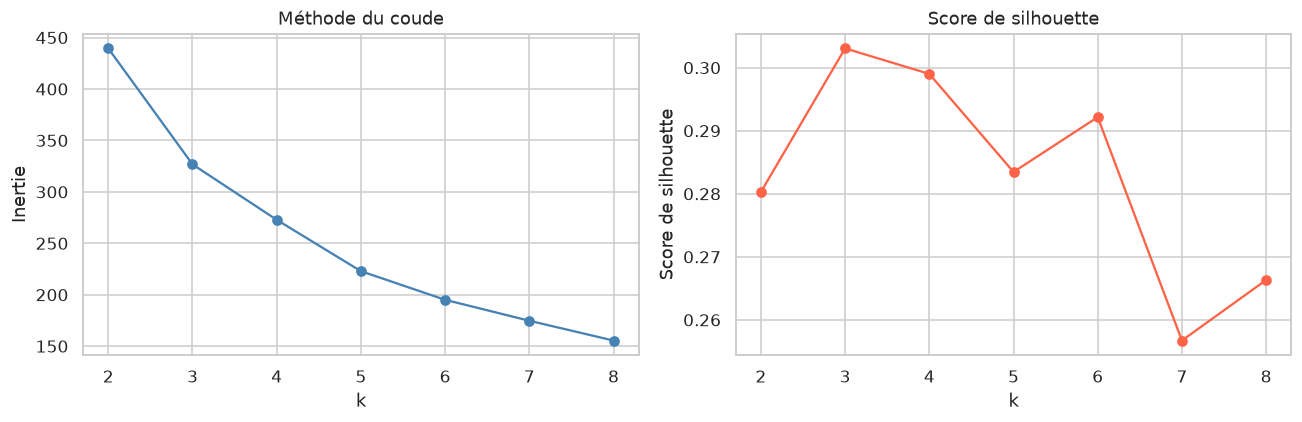

Meilleur k (silhouette) : 3  — silhouette = 0.303


In [ ]:
K_RANGE = range(2, 9)
inertias, sil_scores = [], []

for k in K_RANGE:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=20)
    labels = km.fit_predict(X)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X, labels))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(list(K_RANGE), inertias, marker="o", color="steelblue")
ax1.set_xlabel("k")
ax1.set_ylabel("Inertie")
ax1.set_title("Méthode du coude")

ax2.plot(list(K_RANGE), sil_scores, marker="o", color="tomato")
ax2.set_xlabel("k")
ax2.set_ylabel("Score de silhouette")
ax2.set_title("Score de silhouette")

plt.tight_layout()
plt.show()

best_k = list(K_RANGE)[sil_scores.index(max(sil_scores))]
print(f"Meilleur k (silhouette) : {best_k}  — silhouette = {max(sil_scores):.3f}")

## K-Means — ajustement et description

In [19]:
# On peut forcer k ici si le coude suggère autre chose que best_k
K = best_k  # ajustez manuellement si nécessaire (ex. K = 4)

km_final = KMeans(n_clusters=K, random_state=SEED, n_init=50)
agg_eligible = agg_eligible.copy()
agg_eligible["cluster"] = km_final.fit_predict(X)

print(f"K-Means avec k = {K}")
print("Taille des clusters :")
print(agg_eligible["cluster"].value_counts().sort_index())

K-Means avec k = 3
Taille des clusters :
cluster
0    22
1    41
2    60
Name: count, dtype: int64


In [20]:
# Description statistique des clusters
cluster_stats = agg_eligible.groupby("cluster")[FEATURES].mean().round(4)
cluster_stats.columns = [FEATURE_LABELS[c] for c in cluster_stats.columns]
cluster_stats.index.name = "Cluster"
cluster_stats

,Taux d'annulation,Taux de retard à l'arrivée,Retard moyen conditionnel (min),Ratio retards > 30 min,Irrégularité (std mensuelle)
Cluster,,,,,
0,0.0384,0.2118,39.3976,0.4201,0.1012
1,0.0285,0.1463,27.5405,0.2429,0.0561
2,0.0274,0.1317,43.0808,0.4482,0.0557


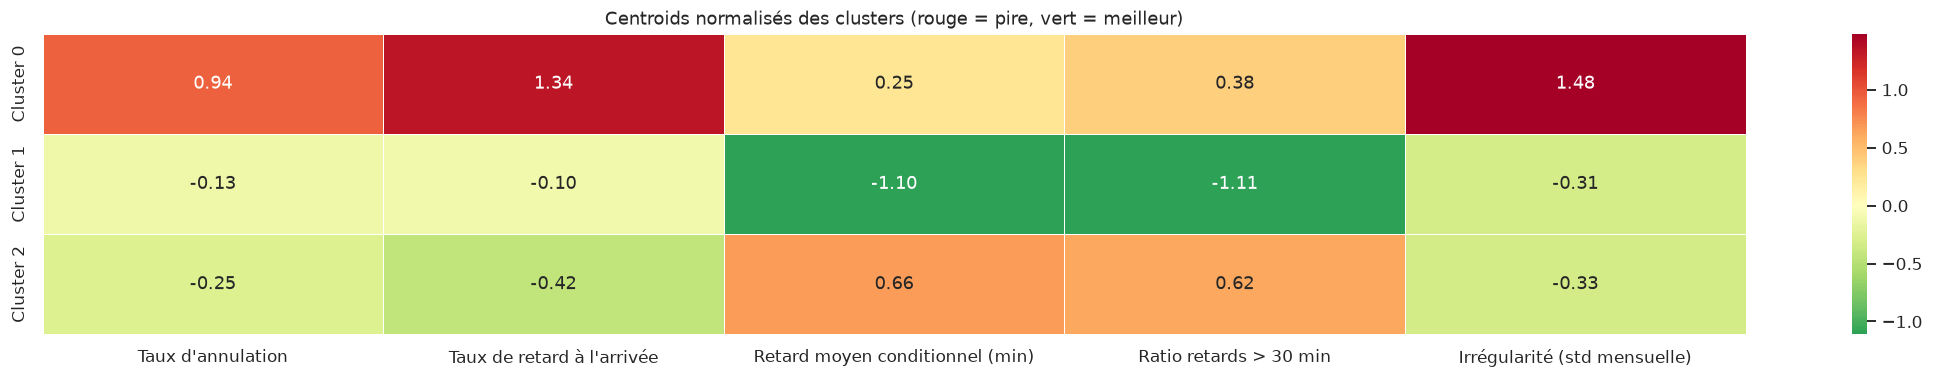

In [22]:
# Heatmap centroids normalisés (pour voir les profils d'un coup d'œil)
centers_df = pd.DataFrame(
    km_final.cluster_centers_,
    columns=[FEATURE_LABELS[f] for f in FEATURES],
    index=[f"Cluster {k}" for k in range(K)],
)

fig, ax = plt.subplots(figsize=(20, K * 0.7 + 1.5))
sns.heatmap(
    centers_df, annot=True, fmt=".2f", cmap="RdYlGn_r", center=0, linewidths=0.5, ax=ax
)
ax.set_title("Centroids normalisés des clusters (rouge = pire, vert = meilleur)")
plt.tight_layout()
plt.show()

## Nommage des profils

On attribue un nom métier à chaque cluster en lisant la heatmap précédente.
Adapter les noms selon le k effectivement trouvé.

In [23]:
# ── Modifier ce dictionnaire selon les profils obtenus ──────────────────────
# Les noms proposés ci-dessous correspondent aux cas k = 4 (à ajuster).
PROFILE_NAMES = {
    0: "Fiable",
    1: "Retards chroniques modérés",
    2: "Retards rares mais sévères",
    3: "Peu fiable",
}
# Si k ≠ 4, compléter / supprimer des entrées.

# Mapper seulement les clusters existants
agg_eligible["profile"] = (
    agg_eligible["cluster"]
    .map({k: v for k, v in PROFILE_NAMES.items() if k < K})
    .fillna(agg_eligible["cluster"].astype(str))
)

print("Répartition par profil :")
print(agg_eligible["profile"].value_counts())

Répartition par profil :
profile
Retards rares mais sévères    60
Retards chroniques modérés    41
Fiable                        22
Name: count, dtype: int64


## Visualisations finales

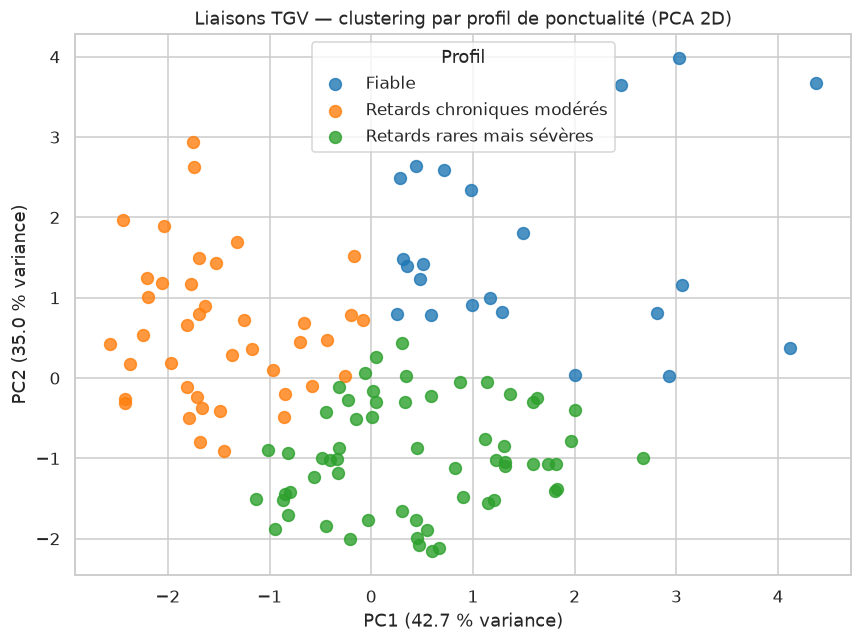

Variance expliquée PC1+PC2 : 77.8 %


In [25]:
# ── Scatter PCA 2D coloré par cluster ────────────────────────────────────────
pca = PCA(n_components=2, random_state=SEED)
coords = pca.fit_transform(X)
var_exp = pca.explained_variance_ratio_ * 100

fig, ax = plt.subplots(figsize=(8, 6))
palette = sns.color_palette("tab10", K)
for c in range(K):
    mask = agg_eligible["cluster"].values == c
    name = PROFILE_NAMES.get(c, str(c))
    ax.scatter(
        coords[mask, 0], coords[mask, 1], label=name, s=60, alpha=0.8, color=palette[c]
    )

ax.set_xlabel(f"PC1 ({var_exp[0]:.1f} % variance)")
ax.set_ylabel(f"PC2 ({var_exp[1]:.1f} % variance)")
ax.set_title("Liaisons TGV — clustering par profil de ponctualité (PCA 2D)")
ax.legend(title="Profil")
plt.tight_layout()
plt.show()

print(f"Variance expliquée PC1+PC2 : {sum(var_exp):.1f} %")

In [ ]:
# ── Bar chart comparatif des profils ─────────────────────────────────────────
stats_plot = (
    agg_eligible.groupby("profile")[FEATURES].mean().rename(columns=FEATURE_LABELS)
)

fig, axes = plt.subplots(1, len(FEATURES), figsize=(18, 4))
for ax, col in zip(axes, stats_plot.columns):
    stats_plot[col].plot(kind="bar", ax=ax, color=palette[:K], edgecolor="white")
    ax.set_title(col, fontsize=9)
    ax.set_xticklabels(stats_plot.index, rotation=30, ha="right", fontsize=8)
    ax.set_ylabel("")
plt.suptitle("Comparaison des profils de ponctualité", y=1.02)
plt.tight_layout()
plt.show()

In [26]:
# ── Top 5 liaisons par profil ────────────────────────────────────────────────
print("═" * 60)
for profile_name, group in agg_eligible.groupby("profile"):
    top5 = group.sort_values("late_arrival_rate")["route"].head(5).tolist()
    print(f"\n✦ {profile_name}")
    for r in top5:
        print(f"   • {r}")

════════════════════════════════════════════════════════════

✦ Fiable
   • MARSEILLE ST CHARLES → MADRID
   • BORDEAUX ST JEAN → TOURCOING
   • MONTPELLIER → LYON PART DIEU
   • PARIS LYON → ITALIE
   • STUTTGART → PARIS EST

✦ Retards chroniques modérés
   • PARIS MONTPARNASSE → ST MALO
   • NANCY → PARIS EST
   • PARIS EST → REIMS
   • PARIS MONTPARNASSE → POITIERS
   • PARIS MONTPARNASSE → RENNES

✦ Retards rares mais sévères
   • BESANCON FRANCHE COMTE TGV → PARIS LYON
   • PARIS EST → NANCY
   • PARIS LYON → LYON PART DIEU
   • LAUSANNE → PARIS LYON
   • ZURICH → PARIS LYON


## Robustesse : la structure est-elle stable ?

On répète le K-Means avec des seeds différents et on mesure si les
assignations changent (adjusted Rand index entre deux runs ≈ 1 = stable).

In [27]:
from sklearn.metrics import adjusted_rand_score

ref_labels = km_final.labels_
ari_scores = []
for seed in range(10):
    km_check = KMeans(n_clusters=K, random_state=seed * 7 + 1, n_init=20)
    labels_check = km_check.fit_predict(X)
    ari_scores.append(adjusted_rand_score(ref_labels, labels_check))

print(f"ARI moyen (10 seeds différents) : {np.mean(ari_scores):.3f}")
print(f"ARI min                         : {np.min(ari_scores):.3f}")
print()
if np.mean(ari_scores) > 0.85:
    print("→ Structure stable : les profils sont robustes au tirage aléatoire.")
elif np.mean(ari_scores) > 0.60:
    print(
        "→ Structure modérément stable : les grands profils tiennent mais "
        "quelques liaisons frontières changent de groupe."
    )
else:
    print(
        "→ Structure instable : envisager un k différent ou une autre méthode "
        "(clustering hiérarchique, DBSCAN)."
    )

ARI moyen (10 seeds différents) : 1.000
ARI min                         : 1.000

→ Structure stable : les profils sont robustes au tirage aléatoire.


## 14. Sauvegarde pour l'application Streamlit

In [ ]:
export_cols = (
    ["route", "departure", "arrival", "n_months", "total_planned", "total_run"]
    + FEATURES
    + ["cluster", "profile"]
)

# Rajouter departure/arrival depuis agg_eligible (on les a dans df_normal)
route_meta = df_normal[["route", "departure", "arrival"]].drop_duplicates("route")
result = agg_eligible.merge(route_meta, on="route", how="left")

out_path = PROCESSED_DIR / "route_profiles.parquet"
result[export_cols].to_parquet(out_path, index=False)
print(f"Sauvegardé : {out_path}  ({len(result)} lignes)")
result[export_cols].head(4)

## 15. Conclusions

### Ce qu'on a découvert

*Compléter après avoir exécuté — exemple :*

> On identifie **k = {K} profils de ponctualité** sur {len(agg_eligible)} liaisons TGV éligibles :
> - **Fiable** (~XX liaisons) : taux d'annulation et de retard très bas, grande régularité
>   mois-à-mois. Ce sont souvent les grandes lignes à fort trafic.
> - **Retards chroniques modérés** (~XX liaisons) : taux de retard moyen mais retards peu
>   sévères — le réseau « souffre » régulièrement mais sans catastrophe.
> - **Retards rares mais sévères** (~XX liaisons) : peu de retards mais quand ils
>   surviennent, ils dépassent souvent 30 min — profil typique des longues distances.
> - **Peu fiable** (~XX liaisons) : cumule annulations, retards fréquents et retards sévères.

### Limites et mises en garde

- Les profils sont descriptifs, pas causaux. Un taux élevé peut refléter des
  travaux ponctuels non capturés par nos mois exceptionnels.
- Les petites liaisons (< 24 mois) sont exclues ; leurs profils sont inconnus.
- L'ARI de robustesse doit être ≥ 0.7 pour que les profils soient reportables.
- On utilise la distance euclidienne dans l'espace des 5 indicateurs — les
  corrélations entre features peuvent biaiser les distances (voir PCA).

### Pour la datasheet (section 5 — Uses)

- Ce clustering **ne permet pas** de prédire le retard d'un train individuel.
- Les profils ne sont pas comparables entre services (National / International)
  sans contrôle de la durée.
- Ne pas additionner les trains de différentes liaisons pour obtenir un total
  national (double-comptage).

### Prochaine étape

Transcrire cette logique dans `src/railinsight/analysis/route_profiles.py`
avec POO, type hints, docstrings et tests unitaires.